# evaluation and transfer: Comparison with published methods

**Level:** 3 **Prerequisites:** Evaluation, transfer and limits level 1 **Reading time:** 25 minutes

**Question:** How does the strongest learned baseline compare with the guarded policy on an identical C01 task?

## Objectives

This lesson investigates the question: How does the strongest learned baseline compare with the guarded policy on an identical C01 task?

## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata;

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```

In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")
import sys
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT))
checkpoint_dir = Path(os.environ.get('NEURAXIS_CHECKPOINTS', str(ROOT / 'models/checkpoints')))
planner_model = os.environ.get('NEURAXIS_NOTEBOOK_MODEL')
planner = OllamaPlanner(planner_model) if planner_model else None
sys.path.insert(0, str(ROOT / 'notebooks'))

reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
The notebook reads committed product artifacts. Owner: Neuraxis. Repository: https://github.com/fsantibanezleal/CAOS_Neuraxis. License: Apache-2.0. The JSON is a first-party, frozen experiment artifact; no external benchmark data are redistributed in this notebook;

This notebook reads `data/derived/index.json` and the listed trace artifacts. The method run uses an isolated Reflexmesh case workspace; For learned methods, fetch the exact public release assets with `python -m reflexmesh; Cli fetch-models --destination models/checkpoints --version v0; 01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder; The release manifest verifies asset hashes. Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model;

Artifacts for this lesson:

- `data/derived/index.json` - `data/derived/benchmark-adequacy.json` - `data/derived/research.json` - `data/derived/semantic-transfer/index.json` - `data/derived/semantic-transfer/report.json` - `data/derived/episodes/M01-C01-nominal-40000; - `data/derived/episodes/M04-C01-nominal-40000; - `data/derived/episodes/M09-C01-nominal-40000; - `data/derived/episodes/M12-C01-nominal-40000;json`

In [2]:
# Load manifest-verified evidence and keep failures in every denominator.
import sys
sys.path.insert(0, str(ROOT / 'notebooks'))
from lesson_support import load_lesson_evidence
selected_methods = trace_methods = ['M01', 'M04']
sample_case, seed = 'C01', 40000
evidence = load_lesson_evidence(
    ROOT, topic='05-evaluation-and-transfer', methods=tuple(trace_methods),
    sample_case=sample_case, seed=seed,
    include_core=False, include_transfer=True,
)
index, audit = evidence['index'], evidence['audit']
records, case_records = evidence['records'], evidence['case_records']
print('Hash-verified records:', len(records), '| case variants:', len(case_records))
transfer, transfer_report = evidence['transfer'], evidence['transfer_report']


Hash-verified records: 2 | case variants: 12


### Compare methods across variants: evaluation and transfer

The comparison must preserve task-family boundaries and denominators, because a core win does not predict transfer performance.

## Method

Tool-use benchmarks such as ToolSandbox, SWE-bench and tau-bench motivate stateful and changing tool conditions, but Neuraxis runs selected local subsets rather than claiming a full benchmark reproduction. Transfer results are separate from the saturated 14,400-episode core and must not be pooled. The paired M01/M04 case display is only a reproducible illustration; evidence for comparative performance comes from complete hashed denominators and the reported held-out transfer lane. The observed M04 advantage is evidence about this suite, not a universal ranking. When outcomes are identical across seeds, a seed-level interval is degenerate; uncertainty should reflect variation among task families or explicitly state that the suite provides no empirical interval. A transfer claim needs a split that prevents near-duplicate task compositions, shared templates or leaked labels from appearing in both training and evaluation partitions. The strongest reproducible conclusion is bounded to the measured software operations, release artifacts and environment assumptions; it should not be generalized to open-world autonomy without new evidence. A useful extension rebuilds the denominator from the manifest and verifies that the transfer split excludes related compositions before comparing methods.

### evaluation and transfer · level 3 | Verify the audit and each trace's bytes before interpreting outcomes.

### evaluation and transfer · level 3 | Execute the released policies and compare the run

### evaluation and transfer · level 3 | Compare the full sequence, not only the first action

### evaluation and transfer · level 3 | Recompute per-variant outcomes from every trace in the case

In [3]:
# Read every seed for the selected case and keep each failed episode in the denominator.
from collections import defaultdict

groups = defaultdict(list)
for row in index["episodes"]:
    if row["case_id"] not in (sample_case,) or row["method_id"] not in selected_methods:
        continue
    raw = (ROOT / "data/derived" / row["path"]).read_bytes()
    episode = json.loads(raw)
    groups[(row["method_id"], row["variant"])].append(int(bool(episode["metrics"]["task_success"])))
for (method_id, variant), values in sorted(groups.items()):
    print(
        method_id,
        variant,
        "successes=",
        sum(values),
        "episodes=",
        len(values),
        "rate=",
        round(sum(values) / len(values), 3),
    )


M01 boundary successes= 10 episodes= 10 rate= 1.0
M01 delayed_observation successes= 10 episodes= 10 rate= 1.0
M01 duplicate_event successes= 10 episodes= 10 rate= 1.0
M01 nominal successes= 10 episodes= 10 rate= 1.0
M01 stale_conflict successes= 10 episodes= 10 rate= 1.0
M01 unavailable_dependency successes= 10 episodes= 10 rate= 1.0
M04 boundary successes= 10 episodes= 10 rate= 1.0
M04 delayed_observation successes= 10 episodes= 10 rate= 1.0
M04 duplicate_event successes= 10 episodes= 10 rate= 1.0
M04 nominal successes= 10 episodes= 10 rate= 1.0
M04 stale_conflict successes= 10 episodes= 10 rate= 1.0
M04 unavailable_dependency successes= 10 episodes= 10 rate= 1.0


### Plot the variant stress without pooling families

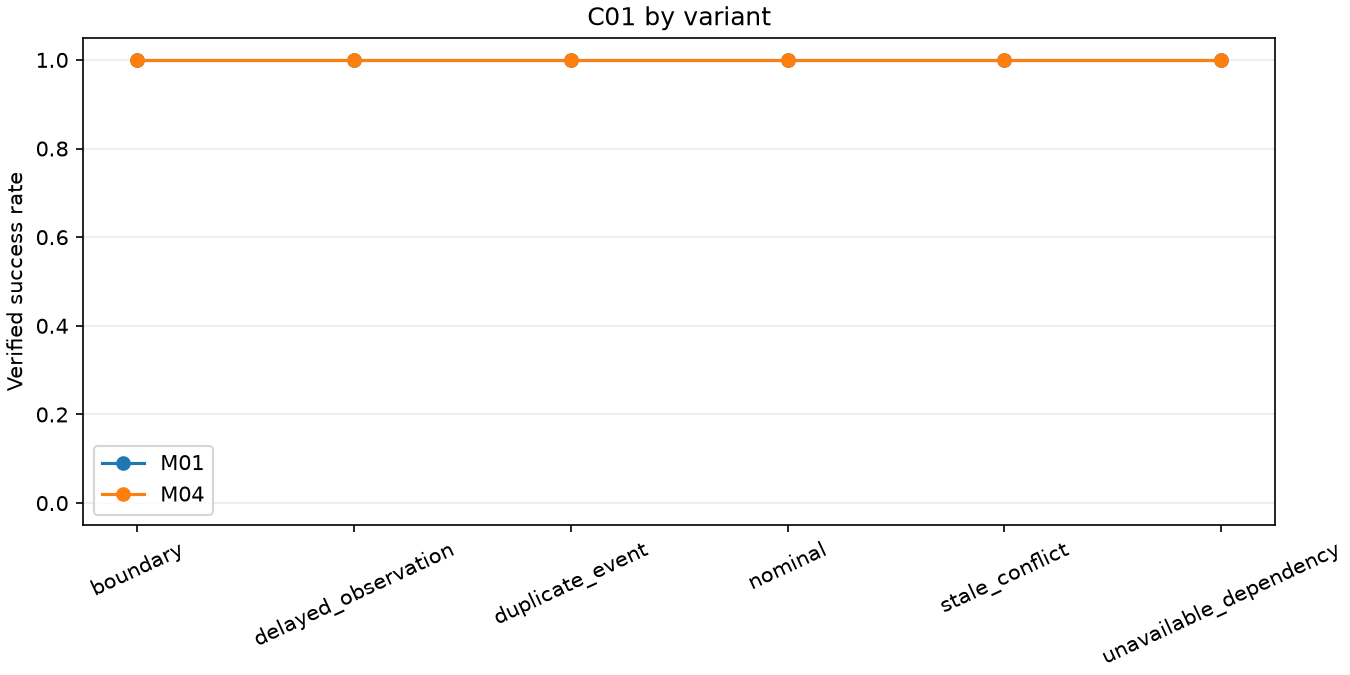

In [4]:
# Each point summarizes the seeds from one case variant, not the full benchmark.
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display

variants = sorted(set(key[1] for key in groups))
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in selected_methods:
    rates = [
        sum(groups[(method_id, variant)]) / len(groups[(method_id, variant)])
        if groups[(method_id, variant)]
        else float("nan")
        for variant in variants
    ]
    ax.plot(variants, rates, marker="o", label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified success rate")
ax.set_title(sample_case + " by variant")
ax.tick_params(axis="x", rotation=25)
ax.grid(axis="y", alpha=0.25)
ax.legend()
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


### Keep semantic transfer in its own lane

C01 is a core example; For chart 1, the denominator is the manifest-hash-verified C01 episode slice loaded above, and failed outcomes remain included. Chart 1 describes the C01 task family not real-world incident rates or unseen software performance. Interpret chart 1 for C01 with its trace and verified postcondition before calling a visual difference a control improvement.

### Report the separately audited semantic-transfer aggregates

The transfer index and episode count are verified against their independent audit before these method totals are displayed.

In [5]:
# Display separate transfer aggregates already hash-checked at the data boundary.
for row in transfer["aggregate_results"]:
    print(
        row["method_id"],
        "successes=",
        round(row["task_success"] * row["episodes"]),
        "/",
        row["episodes"],
        "rate=",
        row["task_success"],
    )
print(
    "Transfer episodes checked:",
    transfer_report["episodes_checked"],
    "| held-out families:",
    len(transfer["cases"]),
)


M01 successes= 0 / 128 rate= 0.0
M02 successes= 0 / 128 rate= 0.0
M03 successes= 0 / 128 rate= 0.0
M04 successes= 2 / 128 rate= 0.015625
M05 successes= 0 / 128 rate= 0.0
M06 successes= 1 / 128 rate= 0.0078125
M07 successes= 0 / 128 rate= 0.0
M08 successes= 6 / 128 rate= 0.046875
M09 successes= 38 / 128 rate= 0.296875
M10 successes= 0 / 128 rate= 0.0
M11 successes= 0 / 128 rate= 0.0
M12 successes= 18 / 128 rate= 0.140625
Transfer episodes checked: 1536 | held-out families: 8


### Read the hash-bound transfer summary

The manifest-bound method and family summaries preserve the full denominator without reopening every episode file.

In [6]:
# Read the hash-bound transfer summaries instead of reopening all 1,536 episode files.
for row in transfer_report["methods"]:
    print(
        row["method_id"],
        "successes=",
        row["successes"],
        "/",
        row["episodes"],
        "rate=",
        round(row["successes"] / row["episodes"], 4),
    )
print("Transfer outcomes by held-out family:")
for row in transfer_report["by_family"]:
    print(row["family"], row["methods"])
print("Persisted M12 paired audit:", transfer_report["m12_paired"])


M01 successes= 0 / 128 rate= 0.0
M02 successes= 0 / 128 rate= 0.0
M03 successes= 0 / 128 rate= 0.0
M04 successes= 2 / 128 rate= 0.0156
M05 successes= 0 / 128 rate= 0.0
M06 successes= 1 / 128 rate= 0.0078
M07 successes= 0 / 128 rate= 0.0
M08 successes= 6 / 128 rate= 0.0469
M09 successes= 38 / 128 rate= 0.2969
M10 successes= 0 / 128 rate= 0.0
M11 successes= 0 / 128 rate= 0.0
M12 successes= 18 / 128 rate= 0.1406
Transfer outcomes by held-out family:
D01 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 0, 'M09': 6, 'M10': 0, 'M11': 0, 'M12': 1}
D02 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 1, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 0, 'M09': 1, 'M10': 0, 'M11': 0, 'M12': 2}
D03 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 1, 'M07': 0, 'M08': 1, 'M09': 9, 'M10': 0, 'M11': 0, 'M12': 6}
D04 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05': 0, 'M06': 0, 'M07': 0, 'M08': 1, 'M09': 3, 'M10': 0, 'M11': 0, 'M12': 0}
D05 {'M01': 0, 'M02': 0, 'M03': 0, 'M04': 0, 'M05

### Full core matrix evidence

The core index is hash-verified against its audit summary. Use its persisted denominators and seed-variation count for the full matrix; the paired win/loss demonstration below is limited to the single C01 nominal seed loaded above. Marginal method rates do not reveal full-matrix paired wins. The separate structural-transfer report is hash-bound to its own index.

In [7]:
# Use the index-bound audit summary for the full matrix and the indexed aggregates for rates.
audit_methods = {row["method_id"]: row for row in audit["methods"]}
print("Episodes checked:", audit["episodes_checked"])
print("Seed-variable case-variant-method cells:", audit["seed_variable_cells"], "/", audit["case_variant_method_cells"])
for row in sorted(index["aggregate_results"], key=lambda value: value["method_id"]):
    audit_row = audit_methods[row["method_id"]]
    print(row["method_id"], audit_row["successes"], "/", audit_row["episodes"], "rate=", round(row["task_success"], 4))


Episodes checked: 14400
Seed-variable case-variant-method cells: 71 / 1440
M01 1200 / 1200 rate= 1.0
M02 1200 / 1200 rate= 1.0
M03 1200 / 1200 rate= 1.0
M04 1200 / 1200 rate= 1.0
M05 1200 / 1200 rate= 1.0
M06 253 / 1200 rate= 0.2108
M07 1170 / 1200 rate= 0.975
M08 664 / 1200 rate= 0.5533
M09 595 / 1200 rate= 0.4958
M10 1200 / 1200 rate= 1.0
M11 1200 / 1200 rate= 1.0
M12 1160 / 1200 rate= 0.9667


### Paired outcome on the declared sample

Compare the selected methods on the same C01, nominal variant and seed 40000. This is one paired observation, not a full-matrix paired estimate.

In [8]:
# Compare the one hash-verified matched case directly; marginal matrix rates do not establish paired wins.
for left, right in [("M01", "M04")]:
    a = int(bool(records[left]["metrics"]["task_success"]))
    b = int(bool(records[right]["metrics"]["task_success"]))
    outcome = (int(a > b), int(a < b), int(a == b))
    print(left, "vs", right, "C01 nominal seed 40000; wins/losses/ties=", outcome)
print("Structural transfer is summarized in its separate hash-bound lane above.")


M01 vs M04 C01 nominal seed 40000; wins/losses/ties= (0, 0, 1)
Structural transfer is summarized in its separate hash-bound lane above.


### evaluation and transfer · L3 | Build the first executable policy

In level 3, construct policy M01 for evaluation and transfer with the public factory and keep its observation contract unchanged before sampling C01.

In [9]:
# Construct the first released policy through the public factory.
primary_id = 'M01'
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M01


### evaluation and transfer · L3 | Execute the primary method on the named case

For the evaluation and transfer comparator run on C01, the evaluation and transfer evaluator runs M01 on C01 and derives success from the independent task postcondition, not from a replayed trace.

In [10]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### evaluation and transfer · L3 | Construct an independent comparison policy

In the matched evaluation and transfer comparison on C01, create M04 as a fresh object so recurrent state from M01 cannot leak into the matched comparison.

In [11]:
# Create a fresh policy object for the matched comparison.
secondary_id = 'M04'
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M04


### evaluation and transfer · L3 | Run the comparison under identical conditions

This level 3 comparison runs M04 on the same C01, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.

In [12]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### evaluation and transfer · L3 | Aggregate the two executed episodes

For the evaluation and transfer comparator run on C01, the package aggregator summarizes two executed evaluation and transfer episodes, and cross-family claims still require the complete benchmark below.

In [13]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### evaluation and transfer · L3 | Fresh policy outcomes

Within this evaluation and transfer comparison (C01), the next plot is computed from the evaluation and transfer episode results just executed for C01 rather than copied from a frozen artifact.

## Comparison
Tool-use benchmarks such as ToolSandbox, SWE-bench and tau-bench motivate stateful and changing tool conditions, but Neuraxis runs selected local subsets rather than claiming a full benchmark reproduction.

This 05 evaluation and transfer lesson, interprets only its declared software case and seed. For the evaluation and transfer comparator run on C01, the executed policy's score does not grant authority: For the evaluation and transfer comparator run on C01, an independent environment check determines whether the requested postcondition was met. In the matched evaluation and transfer comparison on C01, A measured latency belongs beside the outcome because extra computation can increase cost without preventing failure. For the evaluation and transfer comparator run on C01, when two methods are compared, hold case, variant, seed, tool permissions, and success criteria constant. For the evaluation and transfer comparator run on C01, this constraint matters especially when a planner returns plausible text that has not yet produced a verified effect. Missing runs remain missing evidence; In the matched evaluation and transfer comparison on C01, failures and cancellations stay in their original denominators. For the evaluation and transfer comparator run on C01, the example supports a reproducible statement about the recorded protocol, not a universal claim about unfamiliar tools, repositories, or users. For the evaluation and transfer comparator run on C01, readers can change the case or seed and observe where the inference stops applying.

For 05 evaluation and transfer begin by distinguishing policy preference from action authority. For the evaluation and transfer comparator run on C01, the method runs only over the candidate set supplied by the declared environment, and the environment's independent postcondition decides whether the task succeeded. In this 05 evaluation and transfer example, inspect the episode result together with decision latency; For the evaluation and transfer comparator run on C01, A lower latency cannot compensate for a failed postcondition, and a higher cost is not evidence of better reasoning. For the evaluation and transfer comparator run on C01, if this lesson compares methods, keep task family, variant, seed, input evidence, and permissions matched so that the observed difference has a clear interpretation. The 05 evaluation and transfer measurements cover the recorded software tasks and their frozen protocol. For the evaluation and transfer comparator run on C01, they do not establish reliability on arbitrary repositories, novel tools, changing services, or real users. Within this evaluation and transfer comparison (C01), use the computed values below to answer the notebook question, then check the trace identity and artifact digest before extending the conclusion. This makes the 05 evaluation and transfer exercise reproducible and keeps failure, cancellation, and missing evidence visible instead of silently turning them into success.



### evaluation and transfer · L3 | Execute the XGBoost reference on matched conditions

This level 3 evaluation and transfer reference call executes M04 on C01 with the same nominal seed as the fresh policies, and its score and time form one matched observation.

In [14]:
# Execute the measured XGBoost policy on the identical case specification.
state_art_policy = make_policy("M04", checkpoint_dir, planner=planner)
state_art_result = run_episode(state_art_policy, CaseSpec(sample_case, "nominal", seed))
print("Reference-policy runs:", 1)
print("XGBoost task success:", state_art_result["metrics"]["task_success"])


Reference-policy runs: 1
XGBoost task success: 1


This level 3 evaluation and transfer view describes the recorded environment under its declared case, variant and seed.

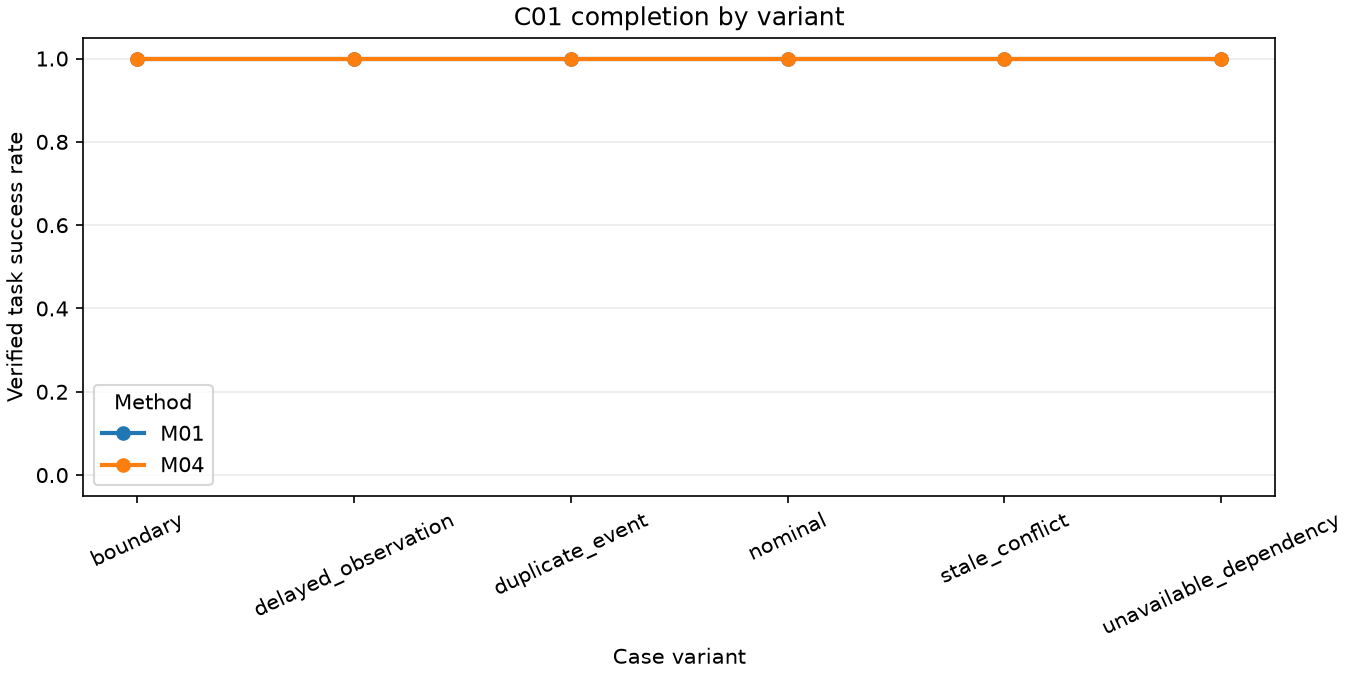

In [15]:
# Compare verified completion rates over every seed in each case variant.
methods_to_plot = selected_methods
variants = sorted({variant for _, variant in case_records})
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
for method_id in methods_to_plot:
    rates = []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        rate = sum(bool(e['metrics']['task_success']) for e in episodes) / len(episodes) if episodes else float('nan')
        rates.append(rate)
    ax.plot(variants, rates, marker='o', linewidth=2, label=method_id)
ax.set_ylim(-0.05, 1.05)
ax.set_ylabel("Verified task success rate")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + " completion by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(title='Método' if False else 'Method')
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


In the matched evaluation and transfer comparison on C01, for evaluation and transfer, these bars show fresh task-postcondition outcomes for M01 and M04 on C01, with success encoded as 1 and failure as 0. Read the case and seed before comparing them. In the matched evaluation and transfer comparison on C01, this controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks;

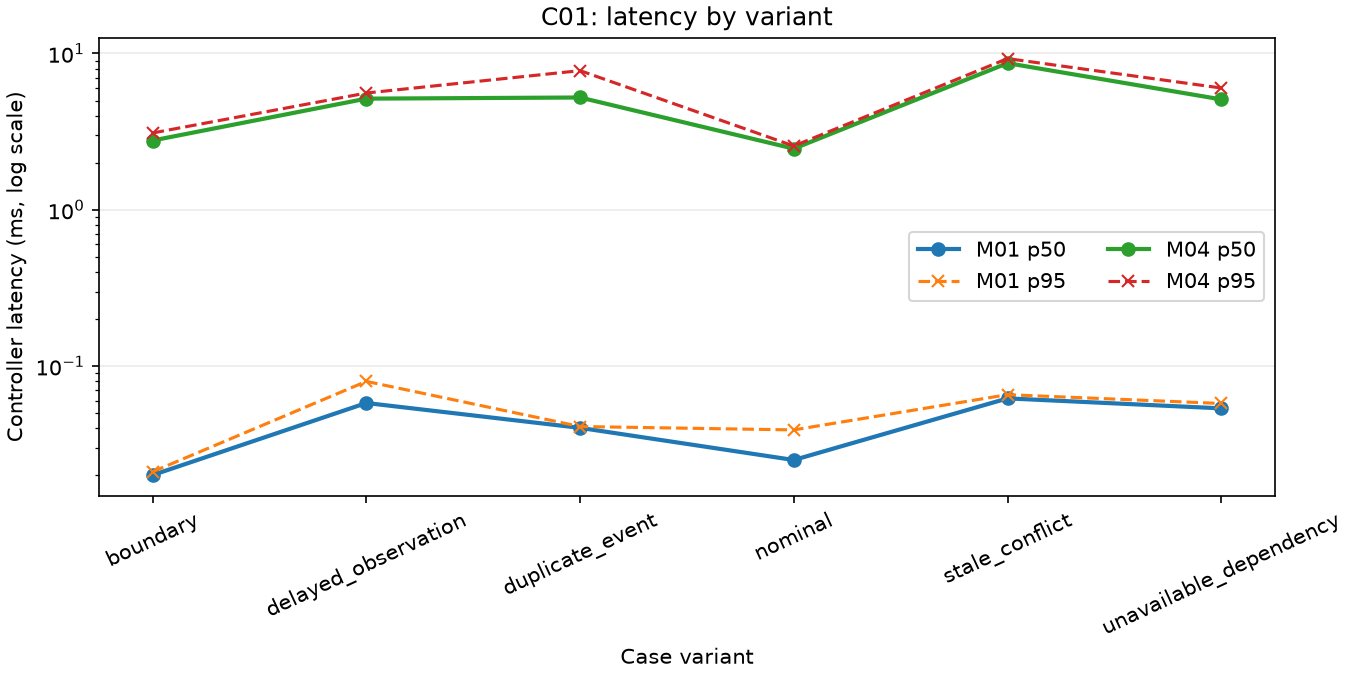

In [16]:
# Compare median and upper-tail controller time across the same case variants.
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
variants = sorted({variant for _, variant in case_records})
methods_to_plot = list(dict.fromkeys(selected_methods + ['M04']))
for method_id in methods_to_plot:
    p50, p95 = [], []
    for variant in variants:
        episodes = case_records.get((method_id, variant), [])
        values = sorted(e['metrics']['controller_ms'] for e in episodes)
        p50.append(values[(len(values) - 1) // 2] if values else float('nan'))
        p95.append(values[min(len(values) - 1, int(.95 * (len(values) - 1)))] if values else float('nan'))
    ax.plot(variants, p50, marker='o', linewidth=2, label=f'{method_id} p50')
    ax.plot(variants, p95, marker='x', linestyle='--', label=f'{method_id} p95')
ax.set_yscale('log')
ax.set_ylabel("Controller latency (ms, log scale)")
ax.set_xlabel("Case variant")
ax.set_title(sample_case + ": latency by variant")
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', alpha=.25)
ax.legend(ncol=2)
image_buffer = BytesIO()
fig.savefig(image_buffer, format='png', dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 3 evaluation and transfer chart reads canonical M01/M04 records for C01, nominal variant and seed 40000 after the data boundary verifies their hashes.

C01 is a core example;

Chart 3, lesson level 3, summarizes core decision time, with held-out transfer kept in its own denominator for C01.

## Results

**Answer:** The evaluation and transfer level-3 comparison contains 2 fresh policy episodes plus 1 XGBoost M04 comparator on C01; those 3 matched runs do not establish population-level superiority for evaluation and transfer.

The core matrix is saturated: In the matched evaluation and transfer comparison on C01, seven methods solve all 1,200 episodes and only 71/1,440 method/case/variant cells vary by seed; For the evaluation and transfer comparator run on C01, in semantic transfer, M04 solves 24/24 structural cases while M12 solves 21/24; In the matched evaluation and transfer comparison on C01, the larger opaque semantic lane also favors M09 over M12; No learned-superiority claim is supported.

## Summary

A core result and a transfer result answer different questions and must remain separately reported.




## References
- [TOOLSANDBOX](https://arxiv.org/abs/2408.04682) - [SWE](https://arxiv.org/abs/2310.06770) - [TAU2](https://arxiv.org/abs/2506.07982)